<a href="https://colab.research.google.com/github/shijut630-hub/hospital-pharmacy-analysis/blob/main/hospital_pharmacy_analysis.ipynb%20" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np

np.random.seed(1)
items = ["Gloves", "Syringes", "Masks", "Bandages", "IV Fluids", "Gauze"]
df = pd.DataFrame({
    "month": np.random.choice(["Jan","Feb","Mar","Apr","May","Jun"], 120),
    "item": np.random.choice(items, 120),
    "qty_ordered": np.random.randint(50, 500, 120),
    "qty_used": np.random.randint(30, 450, 120),
    "delivery_days": np.random.randint(1, 15, 120),
})

print(df.head())
print(df.shape)
print(df.isna().sum())

  month       item  qty_ordered  qty_used  delivery_days
0   Jun   Syringes          103       440             14
1   Apr     Gloves          481       370             12
2   May      Masks          416        60             11
3   Jan  IV Fluids          494       389              9
4   Feb  IV Fluids          293        94              9
(120, 5)
month            0
item             0
qty_ordered      0
qty_used         0
delivery_days    0
dtype: int64


In [ ]:
# 1. Check for duplicate rows
print(df.duplicated().sum())

# 2. Gap = ordered minus used. Negative means we ran short
df["gap"] = df["qty_ordered"] - df["qty_used"]
df["short"] = df["gap"] < 0

# 3. How many shortages in total?
print(df["short"].sum())

# 4. Shortages for each item, highest first
print(df.groupby("item")["short"].sum().sort_values(ascending=False))

# 5. Average delivery days for each item
print(df.groupby("item")["delivery_days"].mean().round(1))

0
59
item
IV Fluids    12
Gauze        11
Syringes     10
Gloves       10
Bandages      9
Masks         7
Name: short, dtype: int64
item
Bandages     8.3
Gauze        7.2
Gloves       7.2
IV Fluids    6.0
Masks        8.5
Syringes     8.3
Name: delivery_days, dtype: float64


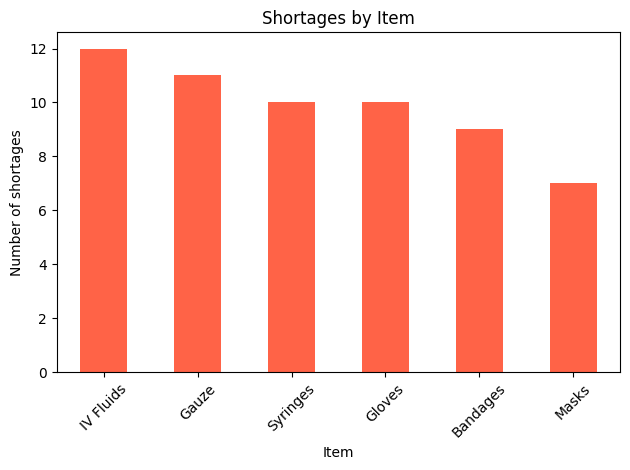

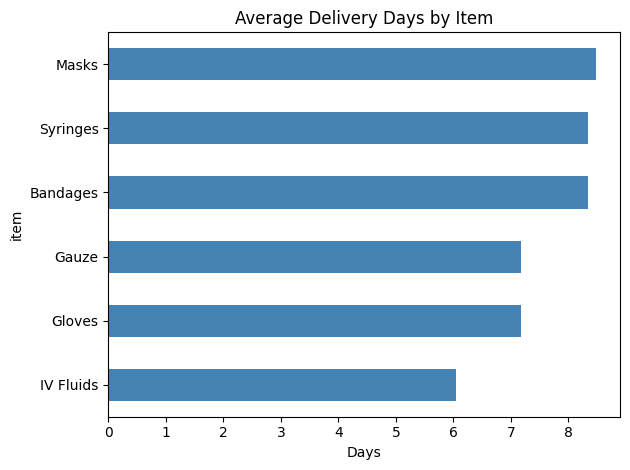

In [ ]:
import matplotlib.pyplot as plt

# Chart 1: shortages for each item
shortages = df.groupby("item")["short"].sum().sort_values(ascending=False)
shortages.plot(kind="bar", color="tomato")
plt.title("Shortages by Item")
plt.xlabel("Item")
plt.ylabel("Number of shortages")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Chart 2: average delivery days for each item
delivery = df.groupby("item")["delivery_days"].mean().sort_values()
delivery.plot(kind="barh", color="steelblue")
plt.title("Average Delivery Days by Item")
plt.xlabel("Days")
plt.tight_layout()
plt.show()

# Hospital Inventory Analysis

**Goal:** Find which medical items run short most often and why.

**Data:** 120 records of orders, usage and delivery days for 6 items.

**What I did:**
- Checked for missing values and duplicates
- Compared ordered and used quantities to find shortages
- Made charts of shortages and delivery days

**Findings:**
- iv fluids had the most shortages (__ times)
- iv fluids had the fastest delivery, but still 6 days
- My conclusion: iv fluids are arrived fast by the all of them but the problem is not slow delivery we ordering less quantity of the product , we can order more quantity then we can fix the shortages accordingly.

**Tools:** Python, Pandas, Matplotlib

In [ ]:
import zipfile
with zipfile.ZipFile("archive.zip") as z:
    z.extractall("data")
    print(z.namelist())

['clinical_details.csv', 'hospital_billing.csv', 'hospital_management_system.xlsx', 'patients.csv', 'pharmacy_prescriptions.csv', 'visits_encounters.csv']


In [ ]:
import os
print(os.listdir())

['.config', 'data', 'archive.zip', 'sample_data']


In [ ]:
import os
for root, folders, files in os.walk("data"):
    for f in files:
            print(os.path.join(root, f))

data/patients.csv
data/hospital_billing.csv
data/visits_encounters.csv
data/pharmacy_prescriptions.csv
data/clinical_details.csv
data/hospital_management_system.xlsx


In [ ]:
import pandas as pd

files = ["patients", "hospital_billing", "visits_encounters",
         "pharmacy_prescriptions", "clinical_details"]
for name in files:
  d = pd.read_csv(f"data/{name}.csv")
  print("-----", name, d.shape)
  print(list(d.columns))

----- patients (5000, 21)
['patient_id', 'first_name', 'last_name', 'gender', 'date_of_birth', 'age', 'blood_group', 'marital_status', 'race_ethnicity', 'residential_zone', 'socioeconomic_tier', 'primary_insurance_provider', 'insurance_policy_id', 'contact_phone', 'emergency_contact_phone', 'street_address', 'zip_code', 'baseline_bmi', 'smoker_status', 'baseline_charlson_comorbidity_index', 'registration_date']
----- hospital_billing (13214, 18)
['bill_id', 'encounter_id', 'patient_id', 'billing_date', 'room_and_board_charges', 'physician_consultation_charges', 'procedure_surgical_charges', 'laboratory_diagnostic_charges', 'pharmacy_charges', 'gross_total_amount', 'discount_contractual_adjustment', 'insurance_covered_amount', 'patient_deductible_copay', 'patient_paid_amount', 'outstanding_balance', 'payment_status', 'claim_status', 'claim_denial_reason']
----- visits_encounters (13214, 18)
['encounter_id', 'patient_id', 'encounter_type', 'admission_datetime', 'discharge_datetime', 'len

In [ ]:
import pandas as pd

rx = pd.read_csv("data/pharmacy_prescriptions.csv")

cols = ["drug_name", "therapeutic_class", "quantity_dispensed",
        "unit_cost_usd", "total_drug_cost", "high_risk_medication_flag"]

print(rx.shape)
print(rx[cols].head())
print(rx[cols].isna().sum())
print(rx.duplicated().sum())

FileNotFoundError: [Errno 2] No such file or directory: 'data/pharmacy_prescriptions.csv'

In [ ]:
import zipfile
with zipfile.ZipFile("archive.zip") as z:
    z.extractall("data")
    print(z.namelist())

['clinical_details.csv', 'hospital_billing.csv', 'hospital_management_system.xlsx', 'patients.csv', 'pharmacy_prescriptions.csv', 'visits_encounters.csv']


In [ ]:
import pandas as pd

rx = pd.read_csv("data/pharmacy_prescriptions.csv")

cols = ["drug_name", "therapeutic_class", "quantity_dispensed",
        "unit_cost_usd", "total_drug_cost", "high_risk_medication_flag"]

print(rx.shape)
print(rx[cols].head())
print(rx[cols].isna().sum())
print(rx.duplicated().sum())

(26715, 16)
               drug_name         therapeutic_class  quantity_dispensed  \
0      Ceftriaxone 1g IV  Cephalosporin Antibiotic                   4   
1   Nitrofurantoin 100mg             Antibacterial                   8   
2  Phenazopyridine 100mg         Urinary Analgesic                  12   
3     Azithromycin 500mg                Antibiotic                  30   
4    Spironolactone 25mg    Aldosterone Antagonist                  30   

   unit_cost_usd  total_drug_cost  high_risk_medication_flag  
0          20.89            83.56                          0  
1           1.11             8.88                          0  
2           0.69             8.28                          0  
3           1.88            56.40                          0  
4           0.48            14.40                          0  
drug_name                    0
therapeutic_class            0
quantity_dispensed           0
unit_cost_usd                0
total_drug_cost              0
high_risk_

In [ ]:
# Top 10 medicines by quantity dispensed
top_drugs = (rx.groupby("drug_name")["quantity_dispensed"].sum()
               .sort_values(ascending=False).head(10))
print(top_drugs)

# Total cost by medicine class
class_cost = (rx.groupby("therapeutic_class")["total_drug_cost"].sum()
                .sort_values(ascending=False).round(0))
print(class_cost)

# Do high-risk medicines cost more per unit?
print(rx.groupby("high_risk_medication_flag")["unit_cost_usd"].mean().round(2))

drug_name
Guaifenesin/Dextromethorphan       83598
Ketorolac 30mg IV                  79260
Piperacillin-Tazobactam 4.5g IV    71556
Ondansetron 8mg IV                 64527
Phenazopyridine 100mg              62310
Metformin 850mg                    58446
Albuterol/Ipratropium Inhaler      52056
Ceftriaxone 1g IV                  51281
Nitrofurantoin 100mg               43096
Oxycodone-Acetaminophen 5/325mg    39406
Name: quantity_dispensed, dtype: int64
therapeutic_class
Chemotherapy / Antineoplastic    4592240.0
Broad-Spectrum Antibiotic        2788387.0
Vasopressor                      2343892.0
Basal Insulin                    1421983.0
Cephalosporin Antibiotic         1159213.0
Bronchodilator                   1017661.0
Glycopeptide Antibiotic          1004489.0
Anticoagulant                     771889.0
Antiemetic                        758183.0
Opioid Analgesic                  588919.0
NSAID Analgesic                   554220.0
IV Crystalloid Fluid              448056.0
Preoper

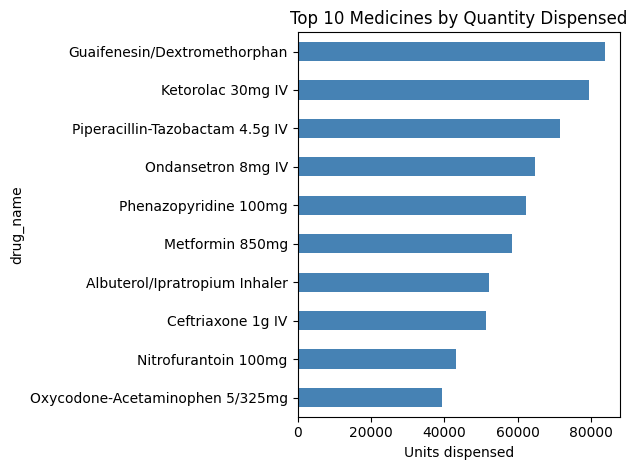

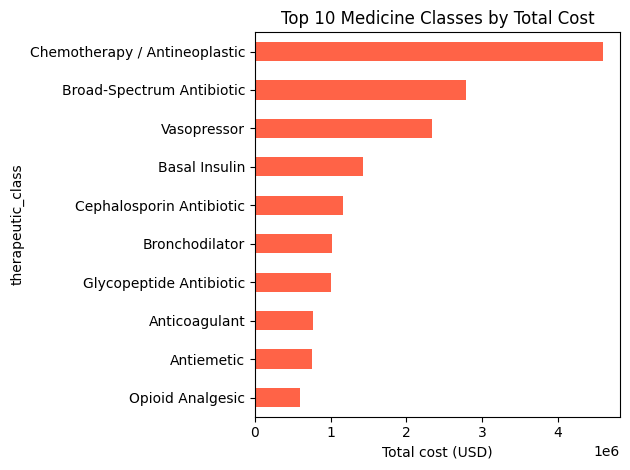

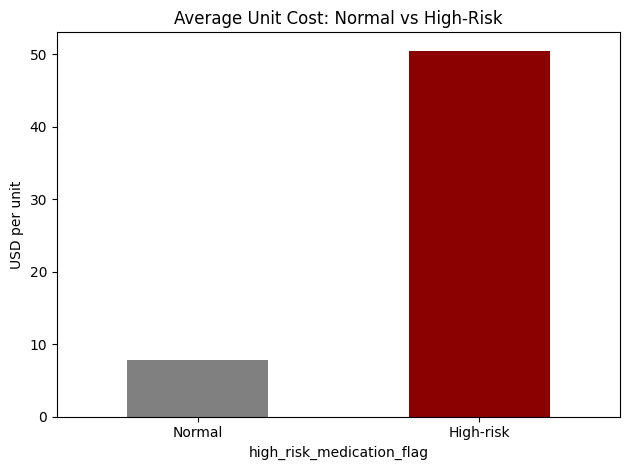

In [ ]:
import matplotlib.pyplot as plt

# Chart 1: top 10 medicines by quantity
top_drugs.sort_values().plot(kind="barh", color="steelblue")
plt.title("Top 10 Medicines by Quantity Dispensed")
plt.xlabel("Units dispensed")
plt.tight_layout()
plt.show()

# Chart 2: top 10 classes by total cost
class_cost.head(10).sort_values().plot(kind="barh", color="tomato")
plt.title("Top 10 Medicine Classes by Total Cost")
plt.xlabel("Total cost (USD)")
plt.tight_layout()
plt.show()

# Chart 3: average unit cost, normal vs high-risk
avg = rx.groupby("high_risk_medication_flag")["unit_cost_usd"].mean()
avg.plot(kind="bar", color=["gray", "darkred"])
plt.xticks([0, 1], ["Normal", "High-risk"], rotation=0)
plt.title("Average Unit Cost: Normal vs High-Risk")
plt.ylabel("USD per unit")
plt.tight_layout()
plt.show()

# Hospital Pharmacy Prescription Analysis

**Goal:** Find which medicines are dispensed the most and which classes cost the most.

**Data:** 26,715 prescription records from a Kaggle hospital management dataset (______). Patient details were not used.

**What I did:**
- Checked for missing values and duplicates
- Grouped prescriptions by medicine and class to find volume and cost
- Compared the unit cost of high-risk and normal medicines
- Made charts of the results

**Findings:**
- Guaifenesin/Dextromethorphan was dispensed the most (83,598 units).
- Chemotherapy / Antineoplastic had the highest total cost (about USD 4.59 million), almost double the next class, Broad-Spectrum Antibiotic (USD 2.79 million).
- High-risk medicines cost about USD 50.52 per unit on average, against USD 7.84 for normal ones.
- Conclusion: The most dispensed medicines are not the most expensive. Total cost is driven by a few costly classes, mainly chemotherapy and high-risk medicines. A hospital trying to reduce pharmacy spending should track these classes closely, while making sure patients still get the treatment they need.

**Tools:** Python, Pandas, Matplotlib